# **1. Resultados**

Este notebook apresenta os resultados do estudo em figuras, com um comentário para cada uma. A pergunta do estudo é **o que melhora a previsão de público do próximo jogo em casa de cada clube da Série A**, nas temporadas de 2022 a 2026. As tabelas usadas aqui foram produzidas nos notebooks 03 a 05.

| seção | figura |
|---|---|
| 2 | público por jogo em casa de cada clube |
| 3 | público relativo por condição do jogo |
| 4 | público por estádio |
| 5 | erro das previsões por modelo |
| 6 | erro da média móvel e do gradient boosting por clube |
| 7 | aumento do erro ao retirar cada grupo de variáveis, na liga e por clube |
| 8 | público observado e previsto nos jogos de 2026 |

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

### **1.1. Configuração**

Todas as figuras seguem o mesmo padrão: título descrevendo o que é mostrado, subtítulo com a forma de leitura, fonte no rodapé e números no formato brasileiro. Azul indica aumento do público ou o modelo final; laranja, redução do público ou o modelo linear; cinza, diferença que não se distingue de zero ou previsões feitas só com a série de público.

In [2]:
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

PROCESSED = ROOT / "data" / "processed"
VIZ = ROOT / "viz"
VIZ.mkdir(parents=True, exist_ok=True)

features = pd.read_csv(PROCESSED / "features.csv", parse_dates=["date", "kickoff_local"])
levels = pd.read_csv(PROCESSED / "exploratory" / "club_levels.csv", index_col=0)
conditions = pd.read_csv(PROCESSED / "exploratory" / "relative_crowd_by_condition.csv")
stadium_moves = pd.read_csv(PROCESSED / "exploratory" / "stadium_moves.csv")
predictions = pd.read_csv(PROCESSED / "forecasting" / "predictions.csv", parse_dates=["date"])
by_club = pd.read_csv(PROCESSED / "forecasting" / "by_club.csv", index_col=0)
ablation_overall = pd.read_csv(PROCESSED / "ablation" / "overall.csv", index_col=0)
ablation_by_club = pd.read_csv(PROCESSED / "ablation" / "by_club.csv")
club_summary = pd.read_csv(PROCESSED / "ablation" / "club_summary.csv", index_col=0)

BLUE, BLUE_LIGHT, ORANGE, ORANGE_LIGHT = "#1d5c8f", "#a9c4dc", "#c2571a", "#e9b99c"
GRAY, GRAY_LIGHT, INK, MUTED, GRID = "#8c8c8c", "#d9d9d9", "#1f1f1f", "#666666", "#ececec"
SOURCE = "Fonte: CBF (calendário e estádios), ESPN (público) e Open-Meteo (clima) · Campeonato Brasileiro Série A, 2022–2026"
GROUP_PT = {"history": "Histórico", "calendar": "Calendário", "weather": "Clima", "form": "Momento", "opponent": "Adversário", "venue": "Estádio"}

plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Avenir Next", "Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 10, "axes.edgecolor": GRAY_LIGHT, "axes.labelcolor": MUTED, "axes.labelsize": 9.5,
    "xtick.color": MUTED, "ytick.color": INK, "xtick.labelsize": 9, "ytick.labelsize": 9.5,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "savefig.dpi": 300,
    "legend.frameon": False, "legend.fontsize": 9,
})


def br(value: float, decimals: int = 0) -> str:
    text = f"{value:,.{decimals}f}"
    return text.replace(",", "§").replace(".", ",").replace("§", ".")


def pct(value: float, decimals: int = 0, sign: bool = True) -> str:
    rounded = round(value * 100, decimals) + 0.0
    text = f"{rounded:{'+' if sign else ''}.{decimals}f}%".replace(".", ",").replace("+0%", "0%").replace("-0%", "0%")
    return text.replace("-", "−")


def thousands(value: float) -> str:
    return f"{br(value / 1000, 1)} mil" if value < 100_000 else f"{br(value / 1000)} mil"


def frame(fig, title: str, subtitle: str, top: float = 0.86, bottom: float = 0.06) -> None:
    fig.text(0.015, 0.985, title, ha="left", va="top", fontsize=15, fontweight="bold", color=INK)
    fig.text(0.015, 0.985 - 0.042 * 11 / fig.get_figheight(), subtitle, ha="left", va="top", fontsize=10.5, color=MUTED, linespacing=1.4)
    fig.text(0.015, 0.012, SOURCE, ha="left", va="bottom", fontsize=7.5, color=GRAY)
    fig.tight_layout(rect=(0, bottom, 1, top))


def save(fig, name: str) -> None:
    fig.savefig(VIZ / name, facecolor="white")
    plt.show()

## **2. Público por clube**

A mediana do Flamengo é de cerca de 60 mil torcedores por jogo; Bragantino e Mirassol ficam abaixo de 6 mil. A faixa entre o 1º e o 3º quartil mostra a variação de cada clube: em Cruzeiro, São Paulo e Fluminense ela passa de 20 mil torcedores. Por causa dessa diferença de tamanho, as comparações das seções seguintes usam o público em relação ao nível recente de cada clube.

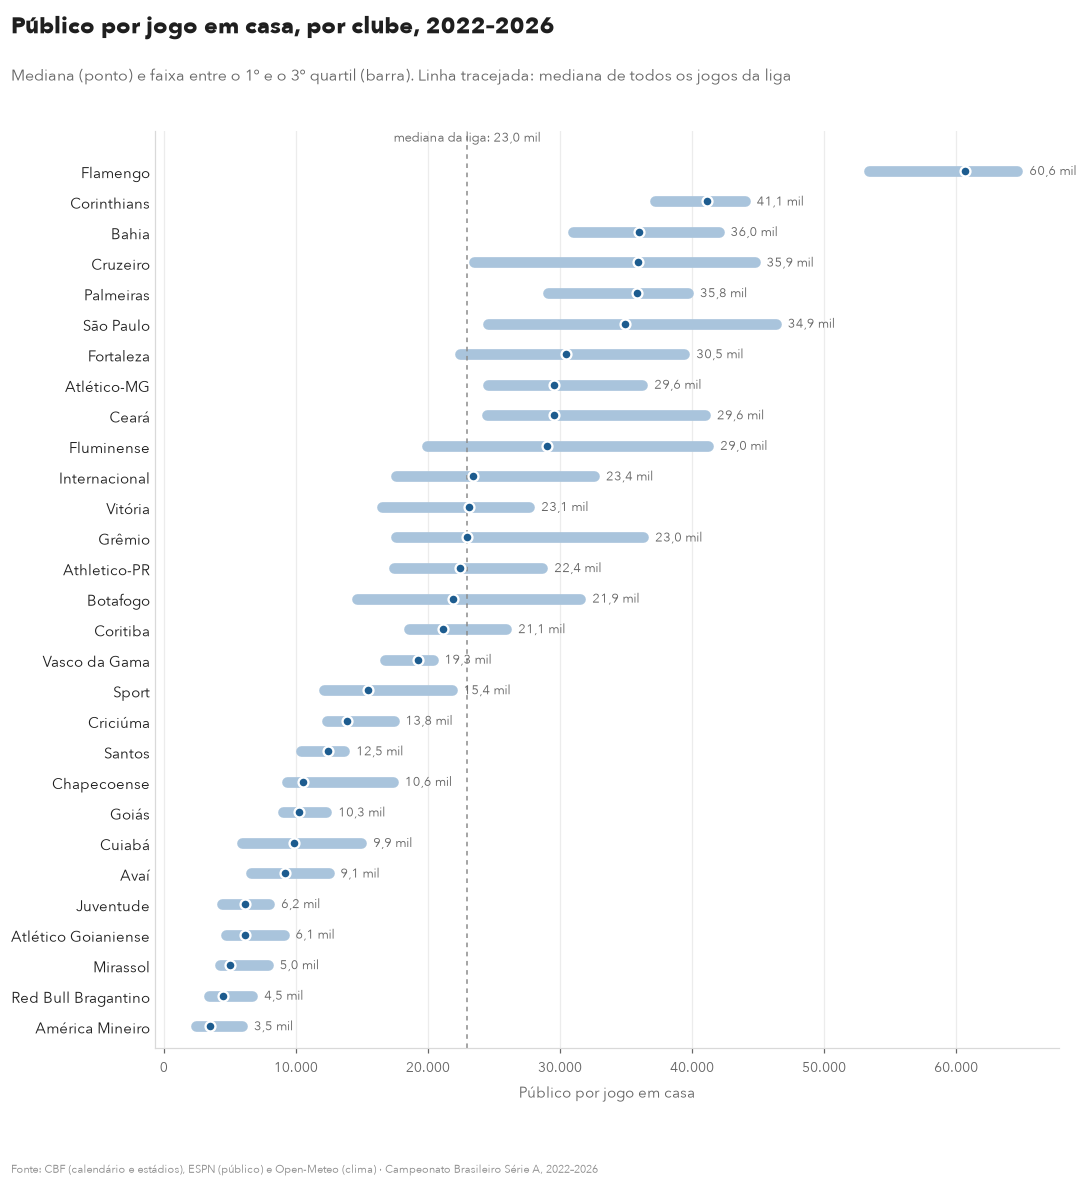

In [3]:
plot = levels.sort_values("median")
league_median = features.loc[features["crowd_status"].eq("regular"), "attendance"].median()
fig, ax = plt.subplots(figsize=(10, 0.3 * len(plot) + 2.2))
y = np.arange(len(plot))
ax.hlines(y, plot["q25"], plot["q75"], color=BLUE_LIGHT, linewidth=7, capstyle="round")
ax.scatter(plot["median"], y, color=BLUE, s=42, zorder=3, edgecolor="white", linewidth=1.5)
for i, (club, row) in enumerate(plot.iterrows()):
    ax.text(row["q75"] + 900, i, thousands(row["median"]), va="center", fontsize=8.5, color=MUTED)
ax.axvline(league_median, color=GRAY, linewidth=1, linestyle=(0, (3, 3)))
ax.text(league_median, len(plot) - 0.2, f"mediana da liga: {thousands(league_median)}", ha="center", va="bottom", fontsize=8.5, color=MUTED)
ax.set_yticks(y, plot.index)
ax.set_ylim(-0.7, len(plot) + 0.3)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: br(v)))
ax.set_xlabel("Público por jogo em casa")
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color=GRID)
ax.set_axisbelow(True)
ratio = plot["median"].max() / league_median
frame(fig, "Público por jogo em casa, por clube, 2022–2026",
      "Mediana (ponto) e faixa entre o 1º e o 3º quartil (barra). Linha tracejada: mediana de todos os jogos da liga", top=0.9)
save(fig, "6_01_publico_por_clube.png")

## **3. Público por condição do jogo**

O público é medido em relação à média dos últimos cinco jogos do clube em casa. Clássicos estaduais têm público cerca de 15% acima dessa média, e jogos contra um dos 12 grandes, cerca de 7% acima. Domingo (+6%) e jogos antes das 17h (+9%) também ficam acima; quarta-feira fica cerca de 16% abaixo. Com menos de 1 ponto por jogo nas últimas cinco rodadas, o público fica cerca de 13% abaixo. Chuva nas quatro horas antes do jogo está associada a público cerca de 12% menor; a temperatura não mostra diferença. Jogos fora do estádio habitual ficam em média abaixo, com grande dispersão, porque o outro estádio pode ser maior ou menor (seção 4).

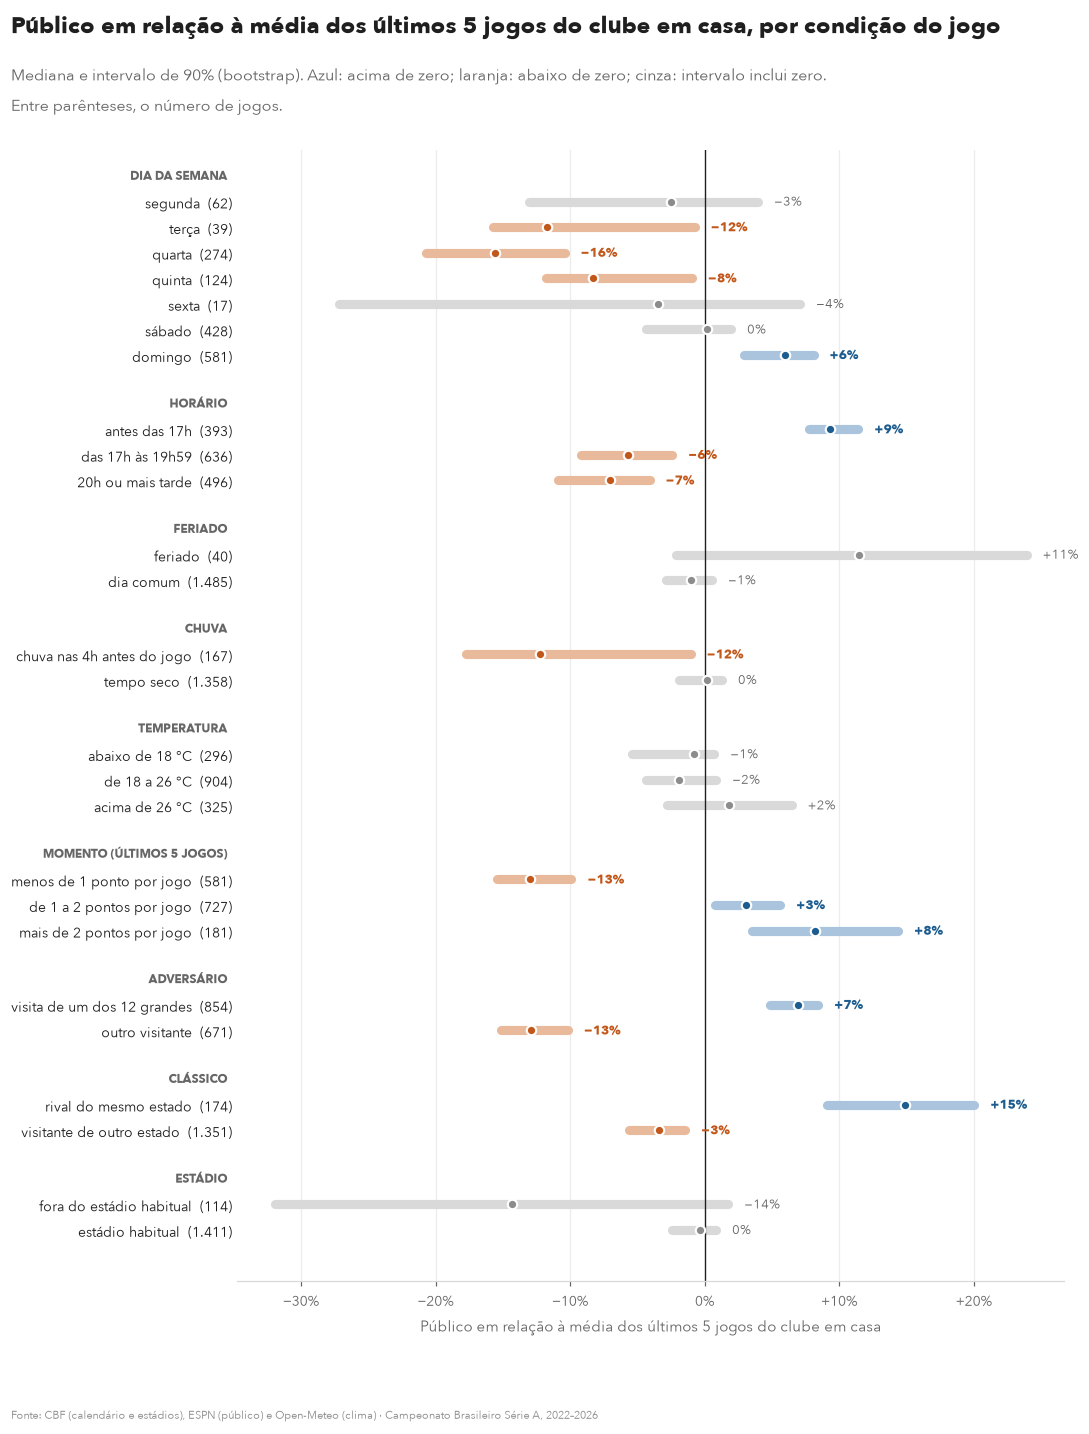

In [4]:
plot = conditions.assign(level_pt=conditions["level"], family_pt=conditions["family"])

fig, ax = plt.subplots(figsize=(10, 0.27 * len(plot) + 0.42 * plot["family_pt"].nunique() + 2.4))
y, ticks, labels, previous = 0.0, [], [], None
for row in plot.itertuples(index=False):
    if row.family_pt != previous:
        y += 0.9 if previous is not None else 0
        ax.text(-0.012, y, row.family_pt.upper(), transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=8, fontweight="bold", color=MUTED)
        y += 1
        previous = row.family_pt
    significant_up, significant_down = row.low > 0, row.high < 0
    color = BLUE if significant_up else ORANGE if significant_down else GRAY
    light = BLUE_LIGHT if significant_up else ORANGE_LIGHT if significant_down else GRAY_LIGHT
    ax.hlines(y, row.low, row.high, color=light, linewidth=6, capstyle="round")
    ax.scatter(row.median, y, color=color, s=38, zorder=3, edgecolor="white", linewidth=1.4)
    ax.text(max(row.high, row.median) + 0.012, y, pct(row.median), va="center", fontsize=8.5, color=color if color != GRAY else MUTED, fontweight="bold" if color != GRAY else "normal")
    ticks.append(y)
    labels.append(f"{row.level_pt}  ({br(row.matches)})")
    y += 1
ax.axvline(0, color=INK, linewidth=0.9)
ax.set_yticks(ticks, labels, fontsize=9)
ax.invert_yaxis()
ax.tick_params(axis="y", length=0)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: pct(v)))
ax.set_xlabel("Público em relação à média dos últimos 5 jogos do clube em casa")
ax.grid(axis="x", color=GRID)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
frame(fig, "Público em relação à média dos últimos 5 jogos do clube em casa, por condição do jogo",
      "Mediana e intervalo de 90% (bootstrap). Azul: acima de zero; laranja: abaixo de zero; cinza: intervalo inclui zero.\nEntre parênteses, o número de jogos.", top=0.9)
save(fig, "6_02_publico_por_condicao.png")

## **4. Público por estádio**

A figura compara o público mediano de cada clube no estádio habitual com o de cada outro estádio onde mandou ao menos dois jogos. O efeito da troca depende do estádio. O Vasco tem público 2,8 vezes maior no Maracanã do que em São Januário, e o Santos, 3,8 vezes maior no Morumbi do que na Vila Belmiro. O Palmeiras tem público 55% menor em Barueri do que no Allianz Parque (Nubank Parque), e o Fluminense, 74% menor em Volta Redonda do que no Maracanã. O modelo recebe essa informação pela capacidade relativa do estádio e pelo público anterior do clube naquele estádio; a média móvel não a recebe.

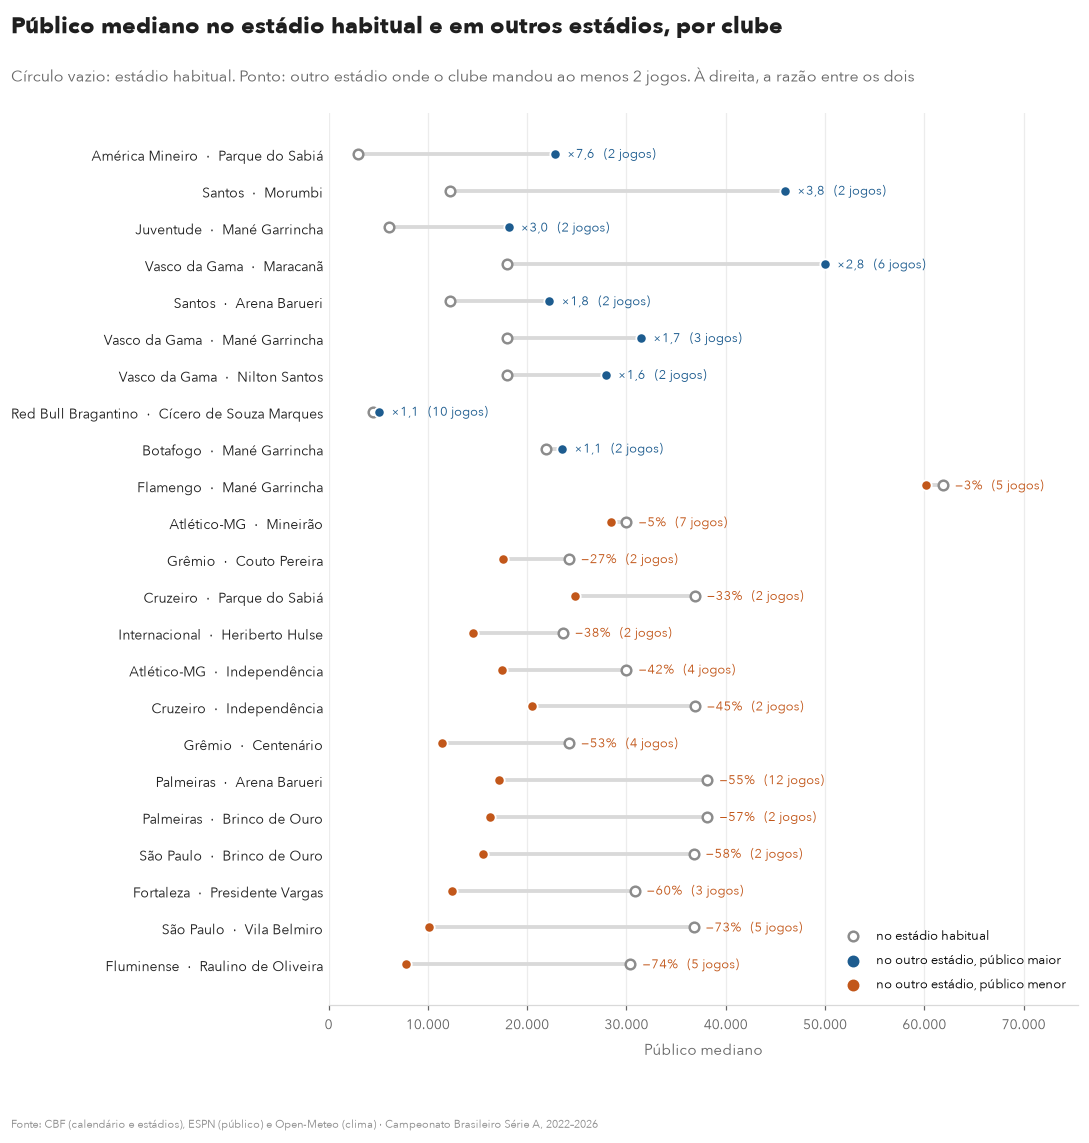

In [5]:
plot = stadium_moves.sort_values("ratio").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 0.36 * len(plot) + 2.2))
for i, row in plot.iterrows():
    color = BLUE if row["ratio"] > 1 else ORANGE
    ax.plot([row["usual_median"], row["median"]], [i, i], color=GRAY_LIGHT, linewidth=2.5, zorder=1)
    ax.scatter(row["usual_median"], i, color="white", edgecolor=GRAY, s=40, linewidth=1.6, zorder=2)
    ax.scatter(row["median"], i, color=color, s=46, zorder=3, edgecolor="white", linewidth=1.2)
    change = f"×{br(row['ratio'], 1)}" if row["ratio"] >= 1 else pct(row["ratio"] - 1)
    ax.text(max(row["usual_median"], row["median"]) + 1200, i, f"{change}   ({br(row['matches'])} jogos)", va="center", fontsize=8.5, color=color)
ax.set_yticks(range(len(plot)), [f"{row.home}  ·  {row.stadium}" for row in plot.itertuples()], fontsize=9)
ax.tick_params(axis="y", length=0)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: br(v)))
ax.set_xlabel("Público mediano")
ax.set_xlim(0, plot[["median", "usual_median"]].max().max() * 1.22)
ax.grid(axis="x", color=GRID)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.scatter([], [], color="white", edgecolor=GRAY, s=40, linewidth=1.6, label="no estádio habitual")
ax.scatter([], [], color=BLUE, s=46, label="no outro estádio, público maior")
ax.scatter([], [], color=ORANGE, s=46, label="no outro estádio, público menor")
ax.legend(loc="lower right", fontsize=8.5)
frame(fig, "Público mediano no estádio habitual e em outros estádios, por clube",
      "Círculo vazio: estádio habitual. Ponto: outro estádio onde o clube mandou ao menos 2 jogos. À direita, a razão entre os dois", top=0.91)
save(fig, "6_03_publico_por_estadio.png")

## **5. Erro das previsões por modelo**

As quatro previsões feitas só com a série de público do clube têm erro médio entre 7,3 e 8,6 mil torcedores por jogo. O último público é a pior delas. A mediana fixa do clube, sem dinâmica, tem erro próximo ao da média móvel (7,7 mil contra 7,6 mil), o que indica que a série informa principalmente o tamanho do clube. Os dois modelos que acrescentam o contexto do jogo (adversário, estádio, momento, calendário e clima) têm erro menor: 6,5 mil na regressão com defasagens e 6,3 mil no gradient boosting, 13% abaixo da melhor previsão feita só com a série.

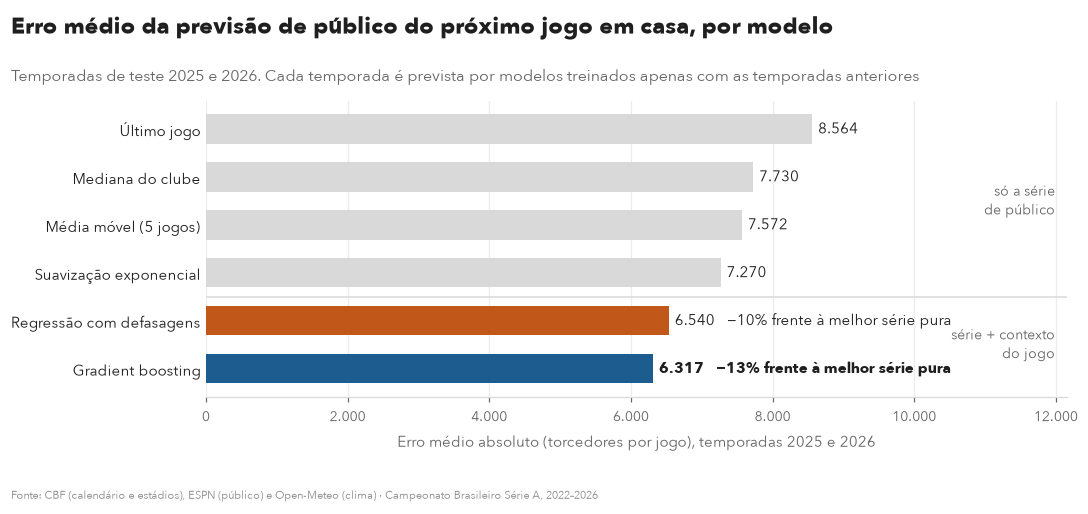

,erro médio
Último jogo,8564.0
Média móvel (5 jogos),7572.0
Suavização exponencial,7270.0
Mediana do clube,7730.0
Regressão com defasagens,6540.0
Gradient boosting,6317.0


In [6]:
MODEL_PT = {
    "Last match": "Último jogo", "Moving average": "Média móvel (5 jogos)", "Exponential smoothing": "Suavização exponencial",
    "Club median": "Mediana do clube", "Lag regression": "Regressão com defasagens", "Gradient boosting": "Gradient boosting",
}
PURE = ["Last match", "Moving average", "Exponential smoothing", "Club median"]
errors = {label: np.mean(np.abs(predictions["attendance"] - predictions[column])) for column, label in {
    "pred_last": "Last match", "pred_ma": "Moving average", "pred_ewm": "Exponential smoothing", "pred_club": "Club median",
    "pred_lag": "Lag regression", "pred_gbm": "Gradient boosting"}.items()}
errors = pd.Series(errors)
best_pure = errors[PURE].min()
order = errors[PURE].sort_values(ascending=False).index.tolist() + ["Lag regression", "Gradient boosting"]
colors = {m: GRAY_LIGHT for m in PURE} | {"Lag regression": ORANGE, "Gradient boosting": BLUE}

fig, ax = plt.subplots(figsize=(10, 4.6))
y = np.arange(len(order))
ax.barh(y, errors[order], color=[colors[m] for m in order], height=0.62)
for i, model in enumerate(order):
    value = errors[model]
    note = "" if model in PURE else f"   {pct(value / best_pure - 1)} frente à melhor série pura"
    ax.text(value + 80, i, f"{br(value)}{note}", va="center", fontsize=9.5, color=INK, fontweight="bold" if model == "Gradient boosting" else "normal")
ax.set_yticks(y, [MODEL_PT[m] for m in order])
ax.invert_yaxis()
ax.tick_params(axis="y", length=0)
ax.set_xlim(0, errors.max() * 1.42)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: br(v)))
ax.set_xlabel("Erro médio absoluto (torcedores por jogo), temporadas 2025 e 2026")
ax.axhline(len(PURE) - 0.5, color=GRAY_LIGHT, linewidth=1)
ax.text(errors.max() * 1.4, len(PURE) / 2 - 0.5, "só a série\nde público", ha="right", va="center", fontsize=9, color=MUTED)
ax.text(errors.max() * 1.4, len(PURE) + 0.5, "série + contexto\ndo jogo", ha="right", va="center", fontsize=9, color=MUTED)
ax.grid(axis="x", color=GRID)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
frame(fig, "Erro médio da previsão de público do próximo jogo em casa, por modelo",
      "Temporadas de teste 2025 e 2026. Cada temporada é prevista por modelos treinados apenas com as temporadas anteriores", top=0.84, bottom=0.08)
save(fig, "6_04_erro_por_modelo.png")
display(errors.rename(MODEL_PT).round(0).to_frame("erro médio"))

## **6. Erro por clube**

O gradient boosting tem erro menor que a média móvel em 21 dos 24 clubes. As maiores reduções estão em clubes que mandam jogos em mais de um estádio (Vasco) e em clubes com pouca história recente na Série A (Mirassol, Sport, Chapecoense). Nos três clubes em que o erro aumenta, o Flamengo tem público quase sempre próximo da lotação do Maracanã, situação em que a média móvel já acerta bem, e Remo e Coritiba têm apenas 8 jogos de teste cada.

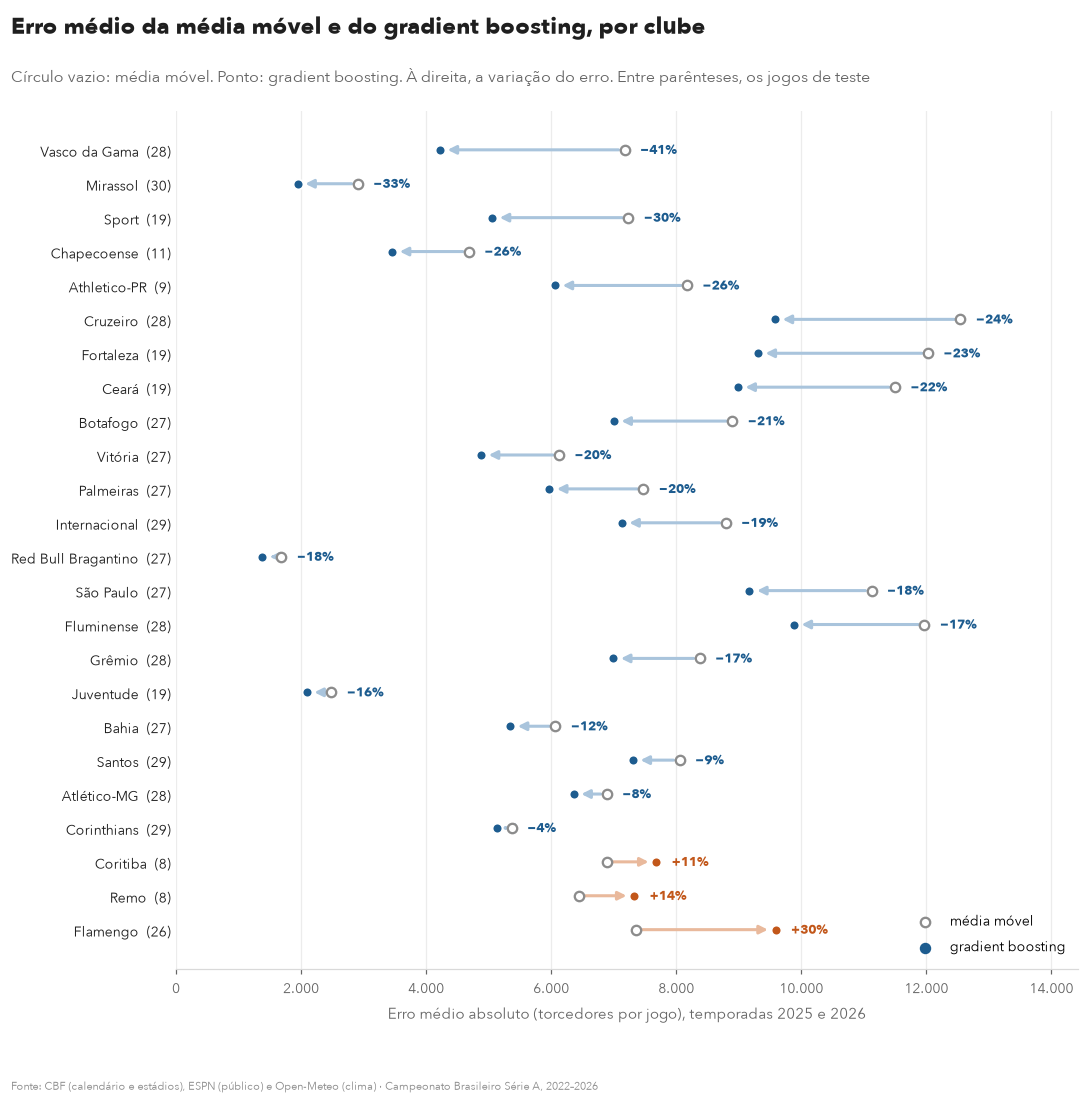

In [7]:
plot = by_club.sort_values("gain_vs_ma")
fig, ax = plt.subplots(figsize=(10, 0.33 * len(plot) + 2.2))
for i, (club, row) in enumerate(plot.iterrows()):
    better = row["Gradient boosting"] < row["Média móvel"]
    color = BLUE if better else ORANGE
    ax.annotate("", xy=(row["Gradient boosting"], i), xytext=(row["Média móvel"], i),
                arrowprops=dict(arrowstyle="-|>", color=BLUE_LIGHT if better else ORANGE_LIGHT, linewidth=2, mutation_scale=11, shrinkA=4, shrinkB=5))
    ax.scatter(row["Média móvel"], i, color="white", edgecolor=GRAY, s=38, linewidth=1.5, zorder=3)
    ax.scatter(row["Gradient boosting"], i, color=color, s=42, zorder=4, edgecolor="white", linewidth=1.2)
    ax.text(max(row["Média móvel"], row["Gradient boosting"]) + 250, i, pct(-row["gain_vs_ma"]), va="center", fontsize=8.5, color=color, fontweight="bold")
ax.set_yticks(range(len(plot)), [f"{club}  ({br(n)})" for club, n in plot["matches"].items()], fontsize=9)
ax.tick_params(axis="y", length=0)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: br(v)))
ax.set_xlabel("Erro médio absoluto (torcedores por jogo), temporadas 2025 e 2026")
ax.set_xlim(0, plot[["Média móvel", "Gradient boosting"]].max().max() * 1.15)
ax.grid(axis="x", color=GRID)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.scatter([], [], color="white", edgecolor=GRAY, s=38, linewidth=1.5, label="média móvel")
ax.scatter([], [], color=BLUE, s=42, label="gradient boosting")
ax.legend(loc="lower right")
n_better = int((plot["gain_vs_ma"] > 0).sum())
frame(fig, "Erro médio da média móvel e do gradient boosting, por clube",
      "Círculo vazio: média móvel. Ponto: gradient boosting. À direita, a variação do erro. Entre parênteses, os jogos de teste", top=0.91)
save(fig, "6_05_erro_por_clube.png")

## **7. Contribuição dos grupos de variáveis**

O modelo foi retreinado cinco vezes, cada vez sem um dos grupos exógenos, e o erro foi comparado com o do modelo completo. No conjunto dos clubes, retirar o adversário ou o estádio aumenta o erro em cerca de 5%, retirar o momento em 3,6% e retirar o calendário em 2,5%; retirar o clima não altera o erro. O histórico de público não entra na figura: sem ele o erro aumenta 69%, porque o modelo deixa de ter a informação do tamanho do clube.

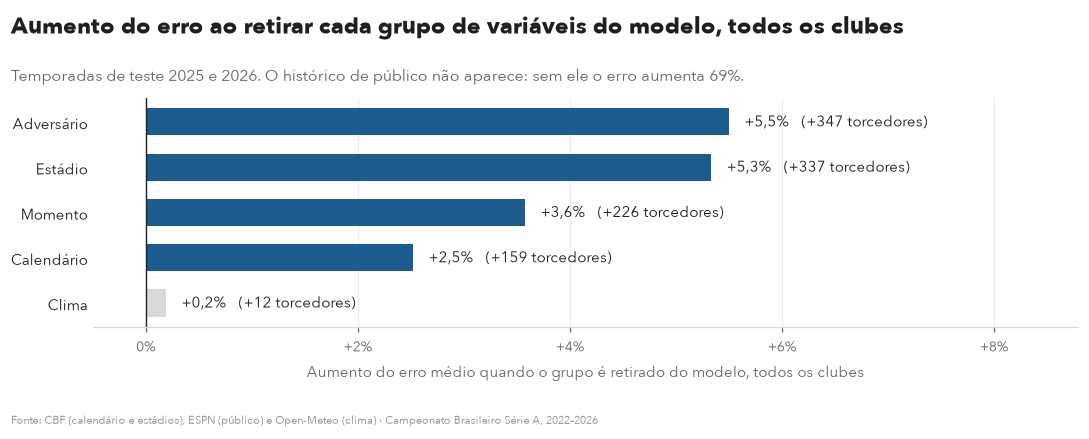

In [8]:
exogenous = ["opponent", "venue", "form", "calendar", "weather"]
plot = ablation_overall.loc[exogenous].sort_values("relative_increase")
fig, ax = plt.subplots(figsize=(10, 3.9))
colors = [BLUE if v > 0.01 else GRAY_LIGHT for v in plot["relative_increase"]]
ax.barh([GROUP_PT[g] for g in plot.index], plot["relative_increase"], color=colors, height=0.6)
for i, (group, row) in enumerate(plot.iterrows()):
    ax.text(max(row["relative_increase"], 0) + 0.0015, i, f"{pct(row['relative_increase'], 1)}   ({'+' if row['increase'] >= 0 else '−'}{br(abs(row['increase']))} torcedores)",
            va="center", fontsize=9.5, color=INK)
ax.axvline(0, color=INK, linewidth=0.9)
ax.set_xlim(min(0, plot["relative_increase"].min()) - 0.005, plot["relative_increase"].max() * 1.6)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: pct(v)))
ax.set_xlabel("Aumento do erro médio quando o grupo é retirado do modelo, todos os clubes")
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color=GRID)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
history = ablation_overall.loc["history"]
frame(fig, "Aumento do erro ao retirar cada grupo de variáveis do modelo, todos os clubes",
      f"Temporadas de teste 2025 e 2026. O histórico de público não aparece: sem ele o erro aumenta {pct(history['relative_increase'], sign=False)}.", top=0.82, bottom=0.08)
save(fig, "6_06_ablacao_geral.png")

### **7.1. Por clube**

O grupo mais útil varia entre os clubes. O estádio é o mais útil para 8 clubes, entre eles Palmeiras, São Paulo, Vasco e Santos, que mandam jogos em mais de um estádio. O adversário é o mais útil para 6, entre eles Bragantino, Corinthians, Ceará e Mirassol. O calendário é o mais útil para Grêmio, Botafogo, Juventude e Vitória, e o momento da equipe, para Atlético-MG e Internacional. Valores em negrito indicam que o grupo reduz o erro do clube em pelo menos 90% das reamostragens bootstrap; o contorno indica o grupo mais útil de cada clube.

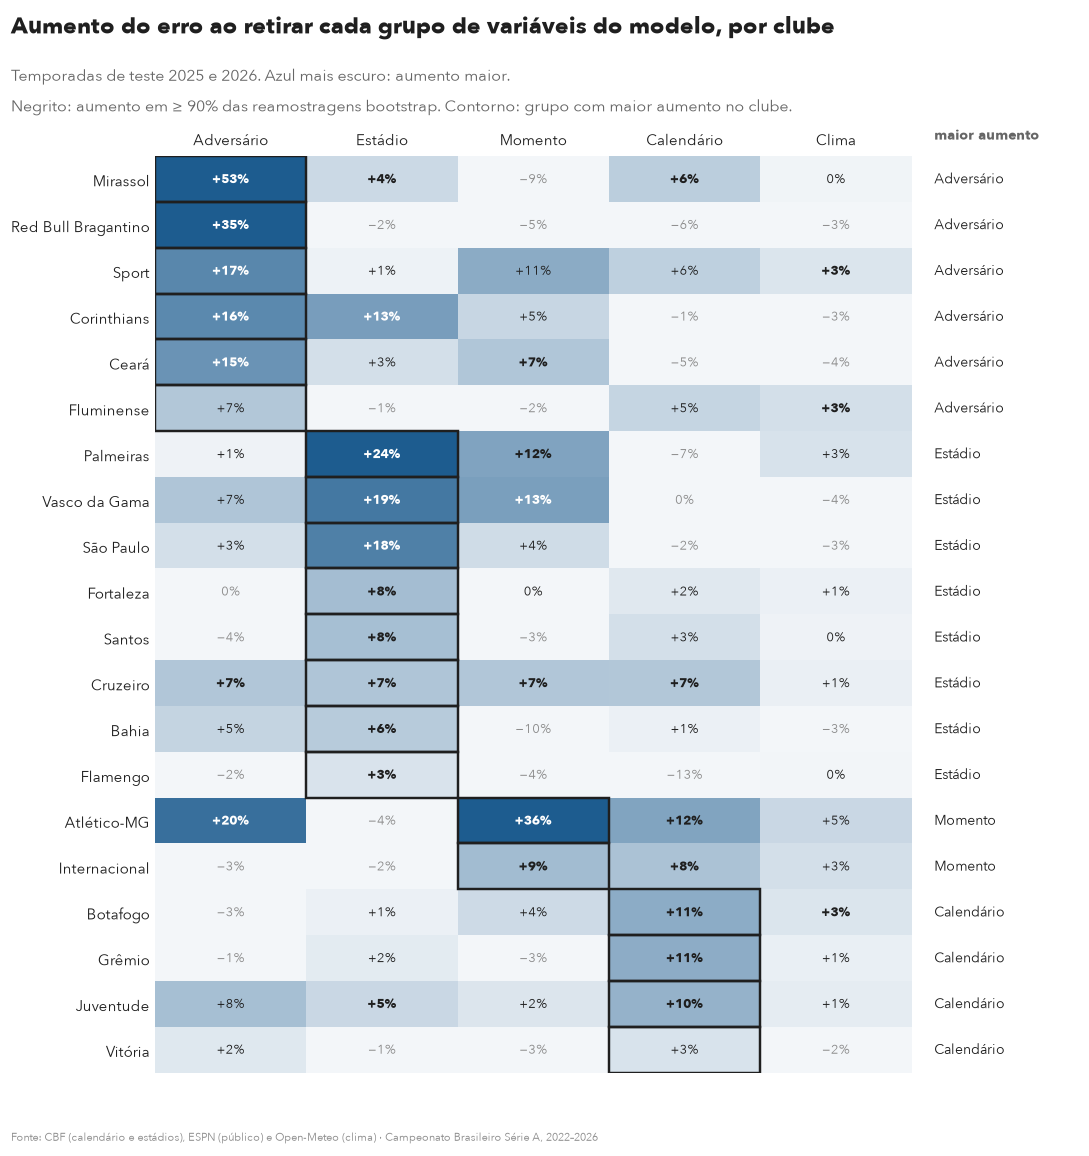

,most_useful_group,increase,share_helps
club,,,
Mirassol,Adversário,0.53,1.00
Atlético-MG,Momento,0.36,1.00
Red Bull Bragantino,Adversário,0.35,0.97
Palmeiras,Estádio,0.24,1.00
Vasco da Gama,Estádio,0.19,0.95
São Paulo,Estádio,0.18,1.00
Sport,Adversário,0.17,0.93
Corinthians,Adversário,0.16,0.98
Ceará,Adversário,0.15,1.00


In [9]:
increase = ablation_by_club.pivot(index="club", columns="group", values="relative_increase")[exogenous]
confidence = ablation_by_club.pivot(index="club", columns="group", values="share_helps")[exogenous]
order = club_summary.sort_values(["most_useful_group", "increase"], ascending=[True, False]).index
group_rank = {g: i for i, g in enumerate(exogenous)}
order = sorted(club_summary.index, key=lambda c: (group_rank[club_summary.loc[c, "most_useful_group"]], -club_summary.loc[c, "increase"]))
values = increase.loc[order].to_numpy()
limit = np.nanquantile(values[values > 0], 0.95)
cmap = LinearSegmentedColormap.from_list("helps", ["#f3f6f9", BLUE])

fig, ax = plt.subplots(figsize=(10, 0.4 * len(order) + 2.6))
ax.imshow(np.clip(values, 0, None), cmap=cmap, vmin=0, vmax=limit, aspect="auto")
for i, club in enumerate(order):
    for j, group in enumerate(exogenous):
        value = increase.loc[club, group]
        strong = confidence.loc[club, group] >= 0.9 and value > 0
        dark = value > limit * 0.55
        ax.text(j, i, pct(value), ha="center", va="center", fontsize=8.5,
                color="white" if dark else (INK if value > 0 else GRAY), fontweight="bold" if strong else "normal")
    best = exogenous.index(club_summary.loc[club, "most_useful_group"])
    ax.add_patch(Rectangle((best - 0.5, i - 0.5), 1, 1, fill=False, edgecolor=INK, linewidth=1.6))
    ax.text(len(exogenous) - 0.35, i, GROUP_PT[club_summary.loc[club, "most_useful_group"]], va="center", fontsize=9, color=INK)
ax.set_xticks(range(len(exogenous)), [GROUP_PT[g] for g in exogenous], fontsize=10, color=INK)
ax.xaxis.tick_top()
ax.set_yticks(range(len(order)), order)
ax.tick_params(length=0)
ax.text(len(exogenous) - 0.35, -0.75, "maior aumento", va="bottom", fontsize=9, color=MUTED, fontweight="bold")
ax.set_xlim(-0.5, len(exogenous) + 0.6)
for spine in ax.spines.values():
    spine.set_visible(False)
frame(fig, "Aumento do erro ao retirar cada grupo de variáveis do modelo, por clube",
      "Temporadas de teste 2025 e 2026. Azul mais escuro: aumento maior.\nNegrito: aumento em ≥ 90% das reamostragens bootstrap. Contorno: grupo com maior aumento no clube.", top=0.9)
save(fig, "6_07_ablacao_por_clube.png")
display(club_summary.assign(most_useful_group=club_summary["most_useful_group"].map(GROUP_PT))[["most_useful_group", "increase", "share_helps"]].round(2))

## **8. Previsões de 2026**

A figura mostra, para quatro clubes, o público observado e o previsto em cada jogo em casa de 2026. Nos jogos do Palmeiras em Barueri e no jogo do Vasco no Maracanã, a previsão do modelo se afasta da média móvel na direção do público observado. A faixa azul é o intervalo de 80%, calibrado na temporada anterior; em 2026 ele contém 89% dos públicos observados. O eixo horizontal mostra a rodada de cada jogo em casa, na ordem das datas em que foram disputados. Os dados de 2026 vão até maio, quando a ESPN deixou de publicar o público.

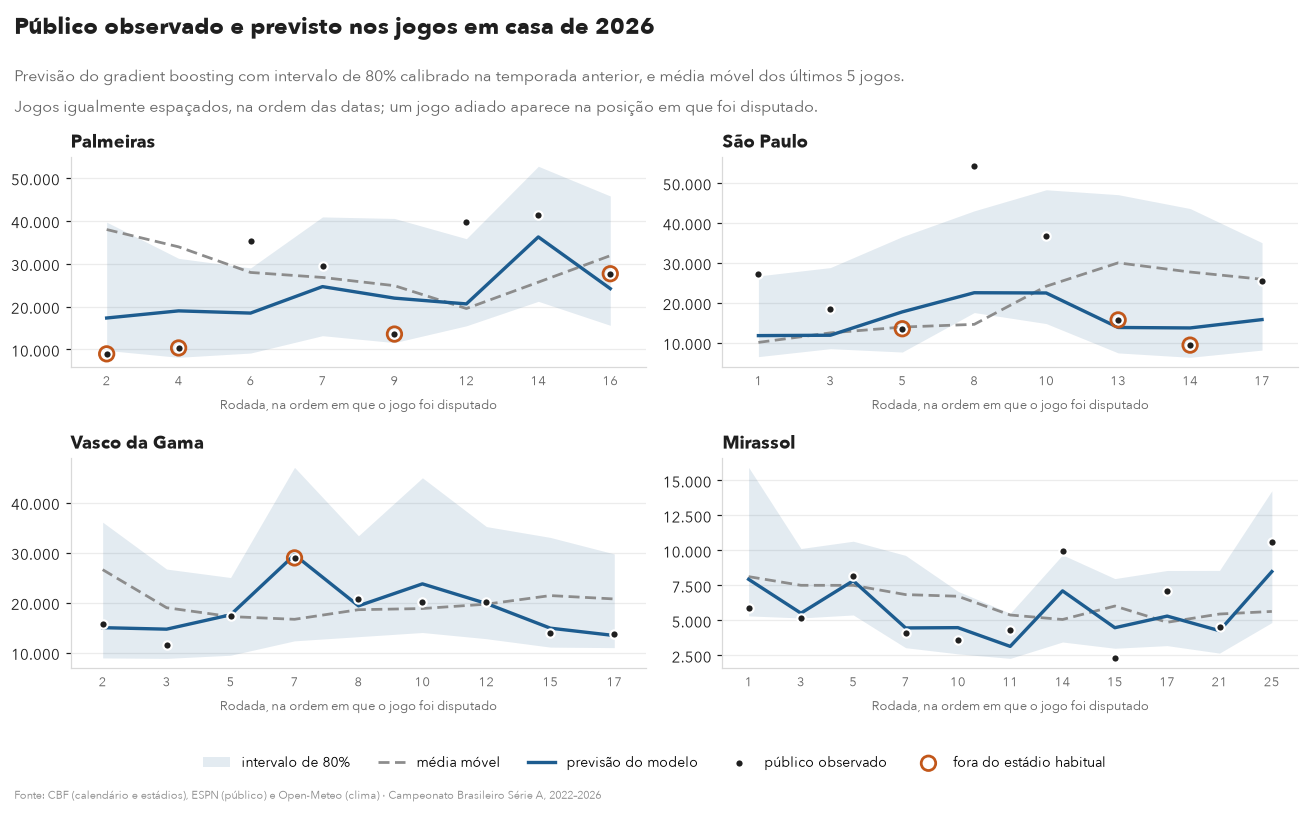

In [10]:
season = predictions[predictions["season"].eq(2026)]
moved = season.groupby("home")["venue_usual"].apply(lambda s: int((s == 0).sum()))
chosen = list(dict.fromkeys(moved.sort_values(ascending=False).index[:2].tolist() + by_club.sort_values("gain_vs_ma", ascending=False).index.tolist()))
chosen = [club for club in chosen if season["home"].eq(club).sum() >= 7][:4]
fig, axes = plt.subplots(2, 2, figsize=(12, 7.4))
for ax, club in zip(axes.flat, chosen):
    f = season[season["home"].eq(club)].sort_values(["date", "round"]).reset_index(drop=True)
    x = np.arange(len(f))
    ax.fill_between(x, f["low_gbm"], f["high_gbm"], color=BLUE, alpha=0.12, linewidth=0, label="intervalo de 80%")
    ax.plot(x, f["pred_ma"], color=GRAY, linewidth=1.8, linestyle=(0, (4, 2)), label="média móvel")
    ax.plot(x, f["pred_gbm"], color=BLUE, linewidth=2.2, label="previsão do modelo")
    ax.scatter(x, f["attendance"], s=30, color=INK, zorder=3, edgecolor="white", linewidth=1.4, label="público observado")
    away = f["venue_usual"].eq(0).to_numpy()
    ax.scatter(x[away], f.loc[away, "attendance"], s=90, facecolor="none", edgecolor=ORANGE, linewidth=1.8, zorder=4, label="fora do estádio habitual")
    ax.set_title(club, loc="left", fontsize=12, fontweight="bold", color=INK)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: br(v)))
    ax.set_xticks(x, [str(int(r)) for r in f["round"]], fontsize=8.5)
    ax.set_xlim(-0.5, len(f) - 0.5)
    ax.set_xlabel("Rodada, na ordem em que o jogo foi disputado", fontsize=8.5)
    ax.tick_params(axis="x", length=0)
    ax.grid(axis="y", color=GRID)
    ax.set_axisbelow(True)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, bbox_to_anchor=(0.5, 0.035))
frame(fig, "Público observado e previsto nos jogos em casa de 2026",
      "Previsão do gradient boosting com intervalo de 80% calibrado na temporada anterior, e média móvel dos últimos 5 jogos.\nJogos igualmente espaçados, na ordem das datas; um jogo adiado aparece na posição em que foi disputado.", top=0.86, bottom=0.1)
save(fig, "6_08_previsoes_2026.png")

## **9. Exportação e auditoria**

| arquivo | conteúdo |
|---|---|
| `viz/6_01_publico_por_clube.png` | público mediano e faixa interquartil de cada clube |
| `viz/6_02_publico_por_condicao.png` | público relativo por dia, horário, clima, momento, adversário e estádio |
| `viz/6_03_publico_por_estadio.png` | público no estádio habitual e nos outros estádios |
| `viz/6_04_erro_por_modelo.png` | erro das previsões só com a série e com o contexto do jogo |
| `viz/6_05_erro_por_clube.png` | erro da média móvel e do modelo em cada clube |
| `viz/6_06_ablacao_geral.png` | aumento do erro ao retirar cada grupo, todos os clubes |
| `viz/6_07_ablacao_por_clube.png` | aumento do erro ao retirar cada grupo, clube a clube |
| `viz/6_08_previsoes_2026.png` | previsões e intervalos jogo a jogo em 2026 |

A auditoria confirma que todas as figuras foram gravadas e que as relações citadas no texto continuam válidas.

In [11]:
FIGURES = [
    "6_01_publico_por_clube.png", "6_02_publico_por_condicao.png", "6_03_publico_por_estadio.png", "6_04_erro_por_modelo.png",
    "6_05_erro_por_clube.png", "6_06_ablacao_geral.png", "6_07_ablacao_por_clube.png", "6_08_previsoes_2026.png",
]
for name in FIGURES:
    assert (VIZ / name).exists(), f"Figura ausente: {name}"
assert errors["Gradient boosting"] < best_pure, "O modelo com contexto deixou de superar as previsões só com a série"
assert abs(ablation_overall.loc["weather", "relative_increase"]) < 0.02, "O clima deixou de ser desprezível; atualizar o texto"
assert ablation_overall.loc[["opponent", "venue"], "relative_increase"].min() > ablation_overall.loc[["form", "calendar", "weather"], "relative_increase"].max(), "A ordem dos grupos mudou; atualizar o texto"
print(f"figuras: {len(FIGURES)} | melhor MAE só com a série: {best_pure:,.0f} | MAE do gradient boosting: {errors['Gradient boosting']:,.0f}")

figuras: 8 | melhor MAE só com a série: 7,270 | MAE do gradient boosting: 6,317
